In [16]:
import os, math, random
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED=42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
PROJECT_ROOT=os.path.abspath("..")  # notebook is in notebooks/
DATA_PROCESSED=os.path.join(PROJECT_ROOT,"data","processed")
MODEL_DIR=os.path.join(PROJECT_ROOT,"models")
EXPERIMENT_DIR=os.path.join(PROJECT_ROOT,"experiments","training")
os.makedirs(MODEL_DIR,exist_ok=True); os.makedirs(EXPERIMENT_DIR,exist_ok=True)
IMG_HEIGHT,IMG_WIDTH=66,200
BATCH_SIZE=64
EPOCHS=40
CAMERA_STEERING_CORRECTION=0.20
print("TensorFlow:",tf.__version__,"GPUs:",tf.config.list_physical_devices("GPU"))
print("Project root:",PROJECT_ROOT)

TensorFlow: 2.21.0 GPUs: []
Project root: C:\Users\user\Neuro Drive


In [17]:
train_df = pd.read_csv(
    os.path.join(DATA_PROCESSED, "train_manifest.csv")
)

val_df = pd.read_csv(
    os.path.join(DATA_PROCESSED, "validation_manifest.csv")
)

print("Train rows:", len(train_df))
print("Validation rows:", len(val_df))

display(train_df.head())
display(val_df.head())

assert len(train_df) > 0 and len(val_df) > 0
assert {"center", "steering", "throttle"}.issubset(val_df.columns)

Train rows: 3294
Validation rows: 1098


,center,left,right,steering,throttle,sampling_weight
0,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.000000,0.052958
1,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.370931,0.052958
2,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,-0.1,0.054634,0.968824
3,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.591308,0.052958
4,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.000000,0.052958


,center,left,right,steering,throttle
0,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.32047
1,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.00000
2,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.00000
3,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.00000
4,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.00000


In [18]:
def preprocess_image(image):
    h,w=image.shape[:2]
    image=image[int(h*.35):h-int(h*.10),:]
    image=cv2.resize(image,(IMG_WIDTH,IMG_HEIGHT),interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

def augment_brightness(image):
    factor=np.random.uniform(.65,1.35)
    return np.clip(image.astype(np.float32)*factor,0,255).astype(np.uint8)

def augment_flip(image,steering):
    if np.random.rand()<.5:
        image=cv2.flip(image,1); steering=-steering
    return image,steering

def load_training_sample(row, training=True):

    steering = float(row["steering"])
    throttle = float(row["throttle"])

    if training:
        camera = np.random.choice(["center", "left", "right"])
        path = str(row[camera])

        if camera == "left":
            steering += CAMERA_STEERING_CORRECTION
        elif camera == "right":
            steering -= CAMERA_STEERING_CORRECTION
    else:
        path = str(row["center"])

    image = cv2.imread(path)

    if image is None:
        raise FileNotFoundError(path)

    image = preprocess_image(image)

    if training:
        image = augment_brightness(image)
        image, steering = augment_flip(image, steering)

    return image, np.float32(steering), np.float32(throttle)

In [19]:
class DrivingSequence(keras.utils.Sequence):

    def __init__(self, dataframe, batch_size=64,
                 shuffle=True, training=True, **kwargs):

        super().__init__(**kwargs)

        self.df = dataframe.reset_index(drop=True).copy()
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.training = training

        self.indices = np.arange(len(self.df))
        self.on_epoch_end()

    def __len__(self):
        return math.ceil(len(self.indices) / self.batch_size)

    def __getitem__(self, batch_index):

        ids = self.indices[
            batch_index * self.batch_size:
            (batch_index + 1) * self.batch_size
        ]

        samples = [
            load_training_sample(
                self.df.iloc[i],
                training=self.training
            )
            for i in ids
        ]

        images, angles, throttles = zip(*samples)

        return (
            np.asarray(images, dtype=np.uint8),
            {
                "steering": np.asarray(angles, dtype=np.float32),
                "throttle": np.asarray(throttles, dtype=np.float32)
            }
        )

    def on_epoch_end(self):

        if self.shuffle:
            np.random.shuffle(self.indices)

train_sequence = DrivingSequence(
    train_df,
    batch_size=BATCH_SIZE,
    shuffle=True,
    training=True
)

val_sequence = DrivingSequence(
    val_df,
    batch_size=BATCH_SIZE,
    shuffle=False,
    training=False
)

print("Training batches:", len(train_sequence))
print("Validation batches:", len(val_sequence))

Training batches: 52
Validation batches: 18


In [20]:
def build_neurodrive_model():
    inputs=keras.Input((IMG_HEIGHT,IMG_WIDTH,3),name="camera_image")
    x=layers.Rescaling(1/255.0,offset=-.5,name="normalize")(inputs)
    x=layers.Conv2D(24,5,strides=2,activation="relu",name="conv1")(x)
    x=layers.Conv2D(36,5,strides=2,activation="relu",name="conv2")(x)
    x=layers.Conv2D(48,5,strides=2,activation="relu",name="conv3")(x)
    x=layers.Conv2D(64,3,activation="relu",name="conv4")(x)
    x=layers.Conv2D(64,3,activation="relu",name="conv5")(x)
    x=layers.Flatten()(x)
    x=layers.Dense(100,activation="relu")(x)
    x=layers.Dense(50,activation="relu")(x)
    x=layers.Dense(10,activation="relu")(x)
    steering_output = layers.Dense(1,activation="linear",name="steering")(x)

    throttle_output = layers.Dense(1,activation="linear",name="throttle")(x)

    return keras.Model(
        inputs=inputs,
        outputs={
            "steering": steering_output,
            "throttle": throttle_output
        },
        name="NeuroDriveCNN"
    )

model=build_neurodrive_model()
model.summary()

Model: "NeuroDriveCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ camera_image (InputLayer)     │ (None, 66, 200, 3)        │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ normalize (Rescaling)         │ (None, 66, 200, 3)        │               0 │ camera_image[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1 (Conv2D)                │ (None, 31, 98, 24)        │           1,824 │ normalize[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2 (Conv2D)                │ (None, 14, 47, 36)        │          21,636 │ conv1[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv3 (Conv2D)                │ (None, 5, 22, 48)         │          43,248 │ conv2[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv4 (Conv2D)                │ (None, 3, 20, 64)         │          27,712 │ conv3[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv5 (Conv2D)                │ (None, 1, 18, 64)         │          36,928 │ conv4[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ flatten_1 (Flatten)           │ (None, 1152)              │               0 │ conv5[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_3 (Dense)               │ (None, 100)               │         115,300 │ flatten_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_4 (Dense)               │ (None, 50)                │           5,050 │ dense_3[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_5 (Dense)               │ (None, 10)                │             510 │ dense_4[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ steering (Dense)              │ (None, 1)                 │              11 │ dense_5[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ throttle (Dense)              │ (None, 1)                 │              11 │ dense_5[0][0]              │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 252,230 (985.27 KB)

 Trainable params: 252,230 (985.27 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),

    loss={
        "steering": "mse",
        "throttle": "mse"
    },

    loss_weights={
        "steering": 1.0,
        "throttle": 1.0
    },

    metrics={
        "steering": [
            keras.metrics.MeanAbsoluteError(name="mae")
        ],
        "throttle": [
            keras.metrics.MeanAbsoluteError(name="mae")
        ]
    }
)
callbacks=[
 keras.callbacks.ModelCheckpoint(os.path.join(MODEL_DIR,"neurodrive_best.keras"),
                                monitor="val_loss",save_best_only=True,verbose=1),
 keras.callbacks.EarlyStopping(monitor="val_loss",patience=8,restore_best_weights=True,verbose=1),
 keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=.5,patience=3,min_lr=1e-7,verbose=1),
 keras.callbacks.CSVLogger(os.path.join(EXPERIMENT_DIR,"training_log.csv"))
]

In [22]:
history = model.fit(
    train_sequence,
    validation_data=val_sequence,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/40
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 998ms/step - loss: 0.1355 - steering_loss: 0.0611 - steering_mae: 0.1836 - throttle_loss: 0.0744 - throttle_mae: 0.1651 
Epoch 1: val_loss improved from None to 0.09786, saving model to C:\Users\user\Neuro Drive\models\neurodrive_best.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 66s 1s/step - loss: 0.1322 - steering_loss: 0.0631 - steering_mae: 0.1860 - throttle_loss: 0.0691 - throttle_mae: 0.1798 - val_loss: 0.0979 - val_steering_loss: 0.0304 - val_steering_mae: 0.0830 - val_throttle_loss: 0.0652 - val_throttle_mae: 0.1950 - learning_rate: 1.0000e-04
Epoch 2/40
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 773ms/step - loss: 0.1238 - steering_loss: 0.0585 - steering_mae: 0.1753 - throttle_loss: 0.0651 - throttle_mae: 0.2006
Epoch 2: val_loss improved from 0.09786 to 0.09749, saving model to C:\Users\user\Neuro Drive\models\neurodrive_best.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 46s 887ms/step - loss: 0.1168 - steering_loss: 0.0540 - steering_mae: 0.1680 - throttle_loss: 0.0626 -

,loss,steering_loss,steering_mae,throttle_loss,throttle_mae,val_loss,val_steering_loss,val_steering_mae,val_throttle_loss,val_throttle_mae,learning_rate
22,0.096809,0.038578,0.137540,0.058037,0.182127,0.093114,0.030302,0.121624,0.060829,0.188942,0.000025
23,0.095204,0.036788,0.134855,0.057833,0.182077,0.093239,0.029843,0.117119,0.061261,0.184307,0.000025
24,0.096141,0.037680,0.133719,0.058344,0.182326,0.093752,0.030599,0.121934,0.061029,0.184528,0.000025
25,0.095336,0.037312,0.134699,0.057992,0.180117,0.093185,0.030124,0.122074,0.061009,0.184637,0.000012
26,0.094174,0.037003,0.133484,0.057329,0.181099,0.094493,0.030662,0.123576,0.061715,0.181528,0.000012


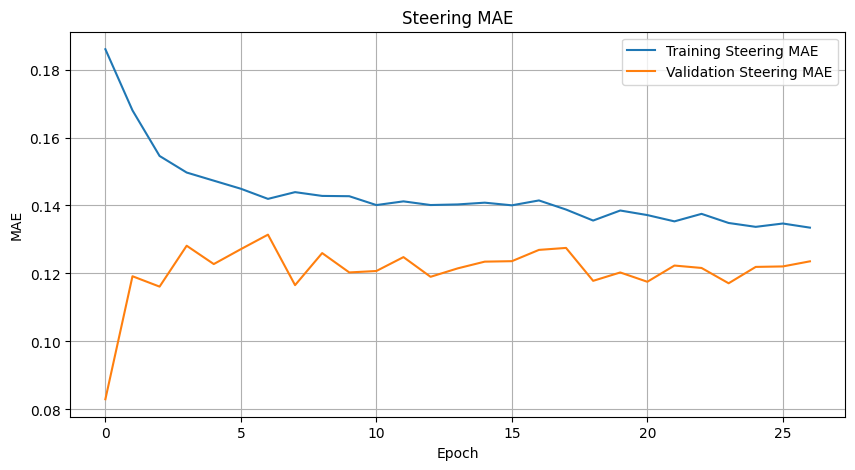

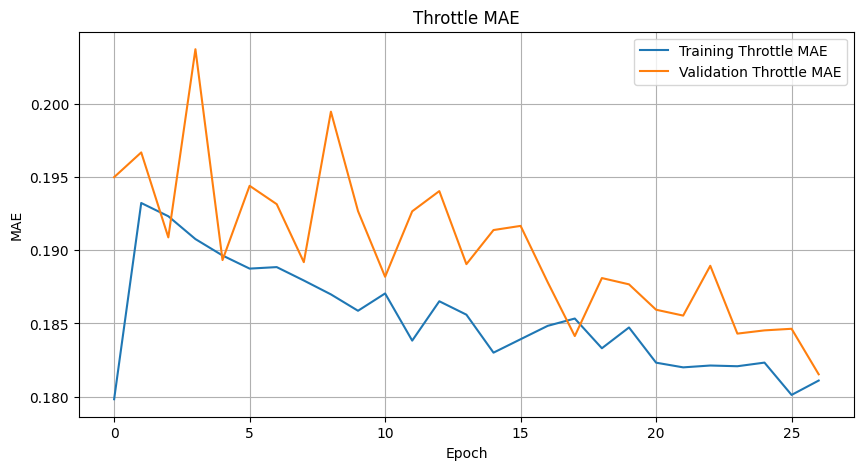

In [23]:
hist=pd.DataFrame(history.history); display(hist.tail())

# Steering MAE
plt.figure(figsize=(10,5))
plt.plot(hist["steering_mae"], label="Training Steering MAE")
plt.plot(hist["val_steering_mae"], label="Validation Steering MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Steering MAE")
plt.legend()
plt.grid(True)
plt.show()


# Throttle MAE
plt.figure(figsize=(10,5))
plt.plot(hist["throttle_mae"], label="Training Throttle MAE")
plt.plot(hist["val_throttle_mae"], label="Validation Throttle MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Throttle MAE")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
model.save(os.path.join(MODEL_DIR,"neurodrive_final.keras"))
hist.to_csv(os.path.join(EXPERIMENT_DIR,"history.csv"),index=False)
print("Saved final model; best checkpoint:",os.path.join(MODEL_DIR,"neurodrive_best.keras"))

Saved final model; best checkpoint: C:\Users\user\Neuro Drive\models\neurodrive_best.keras


In [25]:
# Load test manifest
test_df = pd.read_csv(
    os.path.join(DATA_PROCESSED, "test_manifest.csv")
)

print("Test samples:", len(test_df))
display(test_df.head())

Test samples: 1098


,center,left,right,steering,throttle
0,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,-0.3,0.000000
1,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.000000
2,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,-0.2,0.000000
3,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.917645
4,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.950489


In [26]:
X_test = []
y_test_steering = []
y_test_throttle = []

for _, row in test_df.iterrows():

    image = cv2.imread(row["center"])
    image = preprocess_image(image)

    X_test.append(image)
    y_test_steering.append(row["steering"])
    y_test_throttle.append(row["throttle"])

X_test = np.array(X_test, dtype=np.uint8)

y_test_steering = np.array(y_test_steering, dtype=np.float32)
y_test_throttle = np.array(y_test_throttle, dtype=np.float32)

y_test = {
    "steering": y_test_steering,
    "throttle": y_test_throttle
}

print("X_test:", X_test.shape)
print("Steering:", y_test_steering.shape)
print("Throttle:", y_test_throttle.shape)

X_test: (1098, 66, 200, 3)
Steering: (1098,)
Throttle: (1098,)


In [27]:
best_model = keras.models.load_model(
    os.path.join(MODEL_DIR, "neurodrive_best.keras")
)

test_results = best_model.evaluate(
    X_test,
    y_test,
    return_dict=True,
    verbose=1
)

print("\n--- NeuroDrive V2 Test Results ---")

for metric, value in test_results.items():
    print(f"{metric}: {value:.6f}")

35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 0.0919 - steering_loss: 0.0292 - steering_mae: 0.1168 - throttle_loss: 0.0623 - throttle_mae: 0.1869

--- NeuroDrive V2 Test Results ---
loss: 0.091919
steering_loss: 0.029229
steering_mae: 0.116841
throttle_loss: 0.062261
throttle_mae: 0.186852


35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step


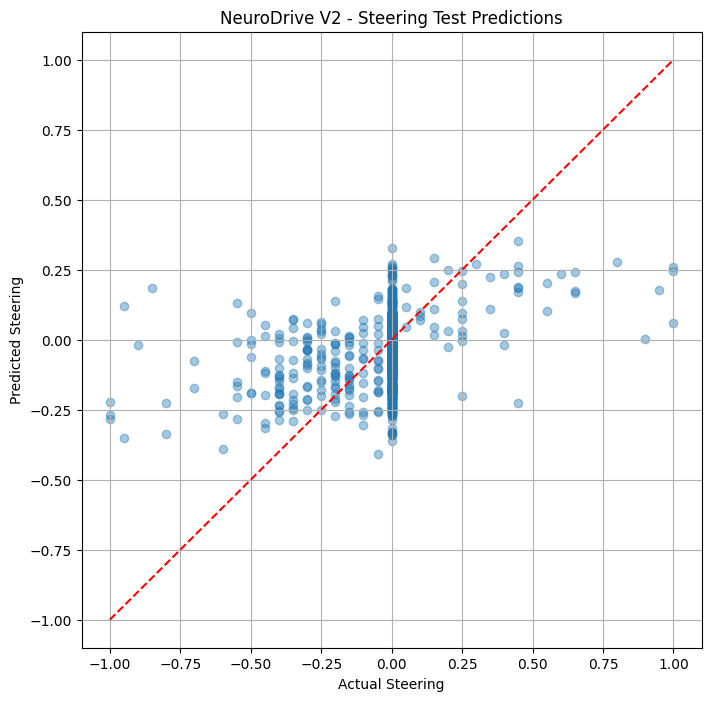

In [28]:
predictions = best_model.predict(X_test)

y_pred_steering = predictions["steering"].flatten()

plt.figure(figsize=(8, 8))

plt.scatter(
    y_test_steering,
    y_pred_steering,
    alpha=0.4
)

plt.plot([-1, 1], [-1, 1], "r--")

plt.xlabel("Actual Steering")
plt.ylabel("Predicted Steering")
plt.title("NeuroDrive V2 - Steering Test Predictions")

plt.grid(True)
plt.show()

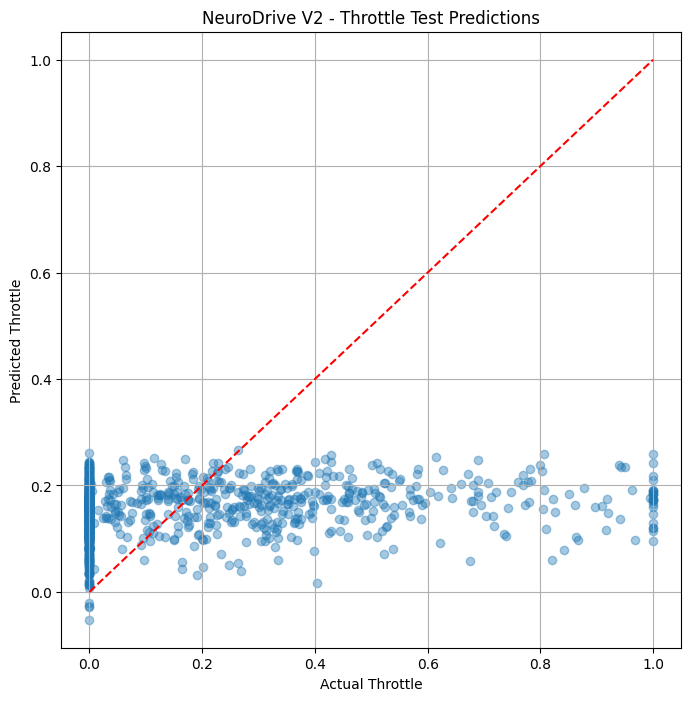

In [29]:
y_pred_throttle = predictions["throttle"].flatten()

plt.figure(figsize=(8, 8))

plt.scatter(
    y_test_throttle,
    y_pred_throttle,
    alpha=0.4
)

plt.plot([0, 1], [0, 1], "r--")

plt.xlabel("Actual Throttle")
plt.ylabel("Predicted Throttle")
plt.title("NeuroDrive V2 - Throttle Test Predictions")

plt.grid(True)
plt.show()

In [30]:
import shutil
from datetime import datetime

# Save V1 model
V2_MODEL_PATH = os.path.join(MODEL_DIR, "neurodrive_v8.keras")

shutil.copy2(
    os.path.join(MODEL_DIR, "neurodrive_best.keras"),
    V2_MODEL_PATH
)

# Save V1 training history
shutil.copy2(
    os.path.join(EXPERIMENT_DIR, "history.csv"),
    os.path.join(EXPERIMENT_DIR, "history_v8.csv")
)

print("V1 model saved:", V2_MODEL_PATH)

V1 model saved: C:\Users\user\Neuro Drive\models\neurodrive_v8.keras
